<a href="https://colab.research.google.com/github/vzavala/StatsBook/blob/master/Python/ch4_example_hypothesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hypothesis testing (Victor Z, UW-Madison, 2024): we draw a random sample from $\mathcal{N}(2,1)$ and
test whether it comes from the (wrong) postulated model $\mathcal{N}(1,1)$ with the z-test and the
Kolmogorov-Smirnov (KS) test; the Lilliefors test checks whether the sample comes from *some* normal RV.
A test returns `h = 1` when it rejects the null hypothesis and `h = 0` when it fails to reject it
(significance level 0.05, as MATLAB's `ztest`, `kstest`, and `lillietest`).

| Book | Python | Meaning |
|---|---|---|
| $x_\omega$, $S$ | `x_omega`, `S` | sample and sample size |
| $\mu$, $\sigma$ | `mu0`, `sigma0` | postulated model $\mathcal{N}(1,1)$ |
| $z=\frac{\bar{x}-\mu}{\sigma/\sqrt{S}}$ | `z` | z-score (test statistic of the z-test) |
| $d=\max_x\,\lvert\hat{F}(x)-F(x)\rvert$ | `d` | KS distance between empirical and model cdf |
| $h$ | `h1`, `h2`, `h3` | test decision (1 = reject the null hypothesis) |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, kstest
from statsmodels.stats.diagnostic import lilliefors

# generate observations from N(2,1)
np.random.seed(0)
S = 100
mu, sigma = 2, 1
x_omega = np.random.normal(mu, sigma, S)

alpha = 0.05            # significance level
mu0, sigma0 = 1, 1      # postulated model N(1,1)

**z-test.** The z-score measures how far the sample mean is from the postulated mean; the p-value is the
probability of a z-score at least this large (in absolute value) if the null hypothesis were true.

In [2]:
z = (np.mean(x_omega) - mu0) / (sigma0 / np.sqrt(S))
p1 = 2 * (1 - norm.cdf(abs(z)))           # two-sided test
h1 = int(p1 < alpha)
print(f"z-test:          z = {z:.3f}, p = {p1:.2e}, h1 = {h1}")

z-test:          z = 10.598, p = 0.00e+00, h1 = 1


**KS test.** The test statistic is the largest distance between the empirical cdf of the sample and the cdf
of the postulated model $\mathcal{N}(1,1)$.

In [3]:
d, p2 = kstest(x_omega, 'norm', args=(mu0, sigma0))
h2 = int(p2 < alpha)
print(f"KS test:         d = {d:.3f}, p = {p2:.2e}, h2 = {h2}")

KS test:         d = 0.425, p = 7.03e-17, h2 = 1


**Lilliefors test.** This test first fits a normal model to the data (sample mean and standard deviation) and
then measures the KS distance to the fitted model; it tests whether the data come from a normal RV.

In [4]:
d3, p3 = lilliefors(x_omega, dist='norm')
h3 = int(p3 < alpha)
print(f"Lilliefors test: d = {d3:.3f}, p = {p3:.3f}, h3 = {h3}")

Lilliefors test: d = 0.064, p = 0.400, h3 = 0


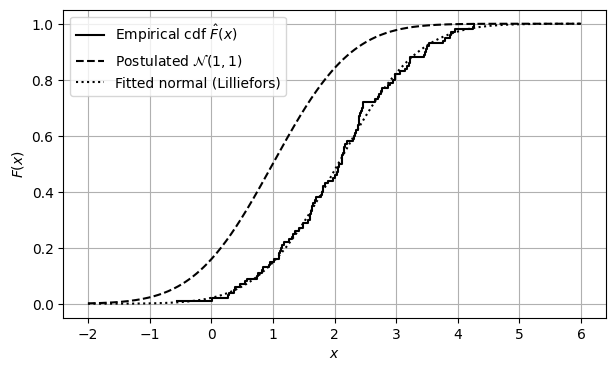

In [5]:
xx = np.linspace(-2, 6, 400)
x_sorted = np.sort(x_omega)
F_hat = np.arange(1, S + 1) / S
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(x_sorted, F_hat, where='post', color='black', label=r'Empirical cdf $\hat{F}(x)$')
ax.plot(xx, norm.cdf(xx, mu0, sigma0), 'k--', label=r'Postulated $\mathcal{N}(1,1)$')
ax.plot(xx, norm.cdf(xx, np.mean(x_omega), np.std(x_omega, ddof=1)), 'k:', label='Fitted normal (Lilliefors)')
ax.set_xlabel('$x$')
ax.set_ylabel('$F(x)$')
ax.grid(True)
ax.legend()
plt.show()

As in the book, the z-test and the KS test reject the null hypothesis that the data come from $\mathcal{N}(1,1)$,
while the Lilliefors test fails to reject that the data come from a normal RV. (The sample differs from the one
drawn in MATLAB, because the two use different random numbers; the conclusions are the same.)